# Assignment 1 - Building a Vision Model with Keras

In this assignment, you will build a simple vision model using Keras. The goal is to classify images from the Fashion MNIST dataset, which contains images of clothing items.

You will:
1. Load and inspect the Fashion MNIST dataset.
2. Run a simple baseline model to establish a performance benchmark.
3. Build and evaluate a simple CNN model, choosing appropriate loss and metrics.
4. Design and run controlled experiments on one hyperparameter (e.g., number of filters, kernel size, etc.) and one regularization technique (e.g., dropout, L2 regularization).
5. Analyze the results and visualize the model's performance.

# 1. Loading and Inspecting the Dataset

Fashion MNIST is a dataset of grayscale images of clothing items, with 10 classes. Each image is 28x28 pixels, like the MNIST dataset of handwritten digits. Keras provides a convenient way to load this dataset. 

In this section, you should:

- [ ] Inspect the shapes of the training and test sets to confirm their size and structure.
- [ ] Convert the labels to one-hot encoded format if necessary. (There is a utility function in Keras for this.)
- [ ] Visualize a few images from the dataset to understand what the data looks like.

In [1]:
from tensorflow.keras.datasets import fashion_mnist
(X_train, y_train), (X_test, y_test) = fashion_mnist.load_data()

# Normalize the pixel values to be between 0 and 1
X_train = X_train.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0

# Classes in the Fashion MNIST dataset
class_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

In [2]:
import numpy as np

# Inspect the shapes of the datasets
print(f"X_train shape: {X_train.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"X_test shape:  {X_test.shape}")
print(f"y_test shape:  {y_test.shape}")
print(f"Pixel values range from {X_train.min():.1f} to {X_train.max():.1f} (already normalized)")
print(f"Classes: {np.unique(y_train)}")
print(f"Training images per class: {np.bincount(y_train)}")
print(f"Test images per class:     {np.bincount(y_test)}")

# Convert labels to one-hot encoding
from tensorflow.keras.utils import to_categorical

print(f"\nBefore one-hot encoding: {y_train[0]} ({class_names[y_train[0]]})")
y_train = to_categorical(y_train, num_classes=10)
y_test = to_categorical(y_test, num_classes=10)
print(f"After one-hot encoding:  {y_train[0]}")
print(f"New label shapes: y_train {y_train.shape}, y_test {y_test.shape}")

X_train shape: (60000, 28, 28)
y_train shape: (60000,)
X_test shape:  (10000, 28, 28)
y_test shape:  (10000,)
Pixel values range from 0.0 to 1.0 (already normalized)
Classes: [0 1 2 3 4 5 6 7 8 9]
Training images per class: [6000 6000 6000 6000 6000 6000 6000 6000 6000 6000]
Test images per class:     [1000 1000 1000 1000 1000 1000 1000 1000 1000 1000]

Before one-hot encoding: 9 (Ankle boot)
After one-hot encoding:  [0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]
New label shapes: y_train (60000, 10), y_test (10000, 10)


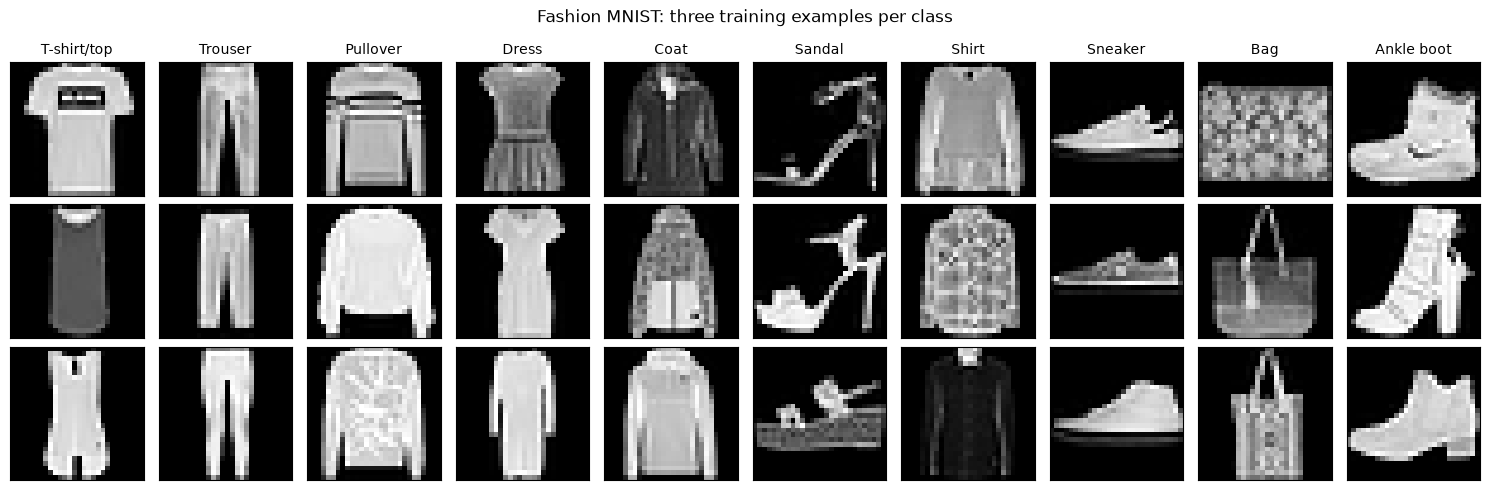

In [ ]:
import matplotlib.pyplot as plt
# Verify the data looks as expected

# Three training images from every class (one column per class)
train_labels = np.argmax(y_train, axis=1)  

fig, axes = plt.subplots(3, 10, figsize=(15, 5))
for class_id in range(10):
    examples = np.where(train_labels == class_id)[0][:3]
    for row, idx in enumerate(examples):
        ax = axes[row, class_id]
        ax.imshow(X_train[idx].reshape(28, 28), cmap="gray")
        ax.set_xticks([])
        ax.set_yticks([])
        if row == 0:
            ax.set_title(class_names[class_id], fontsize=10)
plt.suptitle("Fashion MNIST: three training examples per class")
plt.tight_layout()
plt.show()

Reflection: Does the data look as expected? How is the quality of the images? Are there any issues with the dataset that you notice?

Yes. There are about 60,000 training and 10,000 test images, each 28×28 pixels with one grayscale channel, and the labels are the integers 0–9, which map to the 10 class names. The classes are perfectly balanced (6,000 training and 1,000 test images each), so accuracy is a fair metric, and after normalization the pixel values run from 0 to 1.

The images are clean and consistent as every item is centred on a plain black background and fills most of the frame. However, the resolution is very low, so fine details such as fabric texture, buttons, collars and prints are reduced to a few blurry pixels.

The main issue I notice is that some classes look very similar at this resolution. Shirt, T-shirt/top, Pullover and Coat have almost the same outline, and Sandal, Sneaker and Ankle boot share shapes too, so I expect most mistakes to come from these groups.

# 2. Baseline Model

In this section, you will create a linear regression model as a baseline. This model will not use any convolutional layers, but it will help you understand the performance of a simple model on this dataset.
You should:
- [ ] Create a simple linear regression model using Keras.
- [ ] Compile the model with an appropriate loss function and optimizer.
- [ ] Train the model on the training set and evaluate it on the test set.

A linear regression model can be created using the `Sequential` API in Keras. Using a single `Dense` layer with no activation function is equivalent to a simple linear regression model. Make sure that the number of units in the output layer matches the number of classes in the dataset.

Note that for this step, we will need to use `Flatten` to convert the 2D images into 1D vectors before passing them to the model. Put a `Flatten()` layer as the first layer in your model so that the 2D image data can be flattened into 1D vectors.

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │         7,850 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,850 (30.66 KB)

 Trainable params: 7,850 (30.66 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10


... (17 outputs left out)

Epoch 10/10


422/422 - 1s - 2ms/step - accuracy: 0.8599 - loss: 0.4091 - val_accuracy: 0.8535 - val_loss: 0.4151



Baseline test loss:     0.454
Baseline test accuracy: 84.10%



Test accuracy by class:
  T-shirt/top   81.9%
  Trouser       96.0%
  Pullover      67.9%
  Dress         85.8%
  Coat          84.7%
  Sandal        92.0%
  Shirt         50.2%
  Sneaker       92.6%
  Bag           94.8%
  Ankle boot    95.1%


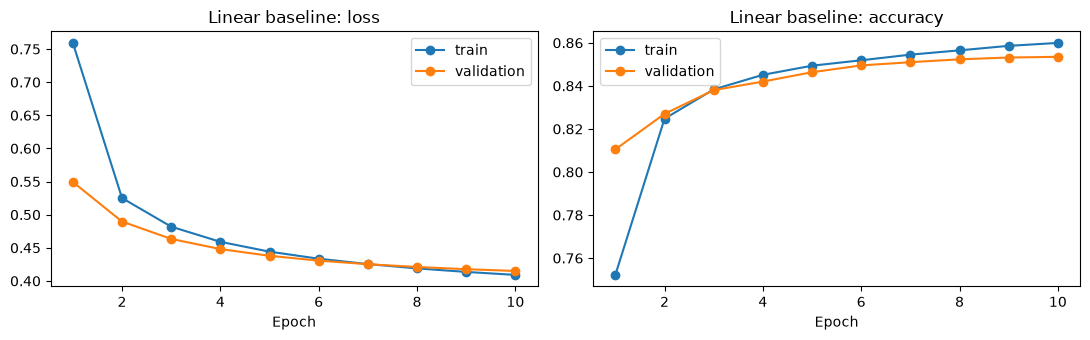

In [ ]:
from keras.models import Sequential
from keras.layers import Dense, Flatten
from keras.layers import Input
from keras.losses import CategoricalCrossentropy
import keras

# Settings shared by every model in this notebook, so the comparisons are fair
EPOCHS = 10
BATCH_SIZE = 128
VALIDATION_SPLIT = 0.1  
SEED = 42              


def plot_history(history, title):
    """Training vs validation loss and accuracy for each epoch (like the curves in Lab 3)."""
    epochs = range(1, len(history.history["loss"]) + 1)
    fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(11, 3.5))
    ax0.plot(epochs, history.history["loss"], marker="o", label="train")
    ax0.plot(epochs, history.history["val_loss"], marker="o", label="validation")
    ax0.set_title(f"{title}: loss")
    ax0.set_xlabel("Epoch")
    ax0.legend(loc="best")
    ax1.plot(epochs, history.history["accuracy"], marker="o", label="train")
    ax1.plot(epochs, history.history["val_accuracy"], marker="o", label="validation")
    ax1.set_title(f"{title}: accuracy")
    ax1.set_xlabel("Epoch")
    ax1.legend(loc="best")
    plt.tight_layout()
    plt.show()


def per_class_accuracy(model, X, y):
    """Share of the test images of each class that the model labels correctly."""
    true_classes = np.argmax(y, axis=1)
    predicted_classes = np.argmax(model.predict(X, verbose=0), axis=1)
    return np.array([np.mean(predicted_classes[true_classes == c] == c) for c in range(10)])


keras.utils.set_random_seed(SEED)

# Create a simple linear regression model
model = Sequential()
# You can use `model.add(<layer>)` to add layers to the model
model.add(Input(shape=(28, 28)))
model.add(Flatten())   # 28x28 image -> vector of 784 pixel values
model.add(Dense(10))   # one output per class and no activation function, so the model is linear
model.summary()

# Compile the model using `model.compile()`
model.compile(
    loss=CategoricalCrossentropy(from_logits=True),
    optimizer="adam",
    metrics=["accuracy"],
)

# Train the model with `model.fit()`
history_baseline = model.fit(
    X_train, y_train,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_split=VALIDATION_SPLIT,
    verbose=2,
)

# Evaluate the model with `model.evaluate()`
baseline_loss, baseline_acc = model.evaluate(X_test, y_test, verbose=0)
print(f"\nBaseline test loss:     {baseline_loss:.3f}")
print(f"Baseline test accuracy: {baseline_acc*100:.2f}%")

baseline_class_acc = per_class_accuracy(model, X_test, y_test)
print("\nTest accuracy by class:")
for name, acc in zip(class_names, baseline_class_acc):
    print(f"  {name:<12} {acc*100:5.1f}%")

plot_history(history_baseline, "Linear baseline")

Reflection: What is the performance of the baseline model? How does it compare to what you expected? Why do you think the performance is at this level?

The baseline reaches **84.10% test accuracy** (test loss 0.454), so it misclassifies 1,590 of the 10,000 test images. That is far better than the 10% we would get by guessing, and better than I expected from a model with no hidden layers and only 7,850 parameters, but it still gets about 1 in 6 images wrong.

I think it performs at this level because the model is linear: each class score is just a weighted sum of the 784 pixel values (essentially one template per class), so it can only separate the classes with straight boundaries. `Flatten` also throws away the 2D layout of the image (as the CNN slides put it, the spatial organization of the input is destroyed), so the model cannot detect edges or shapes and is sensitive to where the item sits in the frame. 

# 3. Building and Evaluating a Simple CNN Model

In this section, you will build a simple Convolutional Neural Network (CNN) model using Keras. A convolutional neural network is a type of deep learning model that is particularly effective for image classification tasks. Unlike the basic neural networks we have built in the labs, CNNs can accept images as input without needing to flatten them into vectors.

You should:
- [ ] Build a simple CNN model with at least one convolutional layer (to learn spatial hierarchies in images) and one fully connected layer (to make predictions).
- [ ] Compile the model with an appropriate loss function and metrics for a multi-class classification problem.
- [ ] Train the model on the training set and evaluate it on the test set.

Convolutional layers are designed to accept inputs with three dimensions: height, width and channels (e.g., RGB for color images). For grayscale images like those in Fashion MNIST, the input shape will be (28, 28, 1).

When you progress from the convolutional layers to the fully connected layers, you will need to flatten the output of the convolutional layers. This can be done using the `Flatten` layer in Keras, which doesn't require any parameters.

X_train shape: (60000, 28, 28, 1), X_test shape: (10000, 28, 28, 1)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 5408)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │       692,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 693,962 (2.65 MB)

 Trainable params: 693,962 (2.65 MB)

 Non-trainable params: 0 (0.00 B)

... (17 outputs left out)

422/422 - 5s - 12ms/step - accuracy: 0.9510 - loss: 0.1405 - val_accuracy: 0.9135 - val_loss: 0.2526


Epoch 10/10


422/422 - 5s - 12ms/step - accuracy: 0.9559 - loss: 0.1269 - val_accuracy: 0.9152 - val_loss: 0.2578



CNN test loss:     0.266
CNN test accuracy: 91.31%
Change vs baseline: +7.21 percentage points
Test errors (out of 10,000): baseline 1590, CNN 869


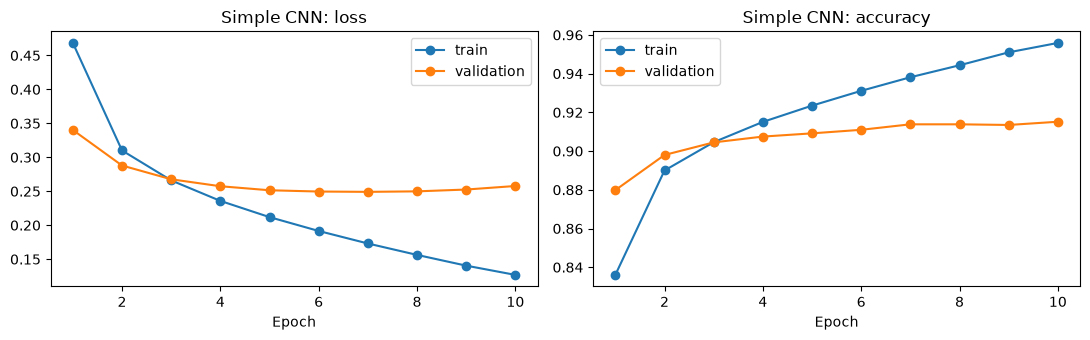

,baseline (%),CNN (%),change (pts)
T-shirt/top,81.9,87.0,5.1
Trouser,96.0,98.2,2.2
Pullover,67.9,87.0,19.1
Dress,85.8,92.2,6.4
Coat,84.7,87.0,2.3
Sandal,92.0,99.2,7.2
Shirt,50.2,73.6,23.4
Sneaker,92.6,94.8,2.2
Bag,94.8,97.9,3.1
Ankle boot,95.1,96.2,1.1


In [ ]:
from keras.layers import Conv2D
from keras.layers import MaxPooling2D
import pandas as pd

# Reshape the data to include the channel dimension
X_train = X_train.reshape(-1, 28, 28, 1)
X_test = X_test.reshape(-1, 28, 28, 1)
print(f"X_train shape: {X_train.shape}, X_test shape: {X_test.shape}")

keras.utils.set_random_seed(SEED)

# Create a simple CNN model
model = Sequential()
model.add(Input(shape=(28, 28, 1)))
model.add(Conv2D(32, kernel_size=(3, 3), activation="relu"))  
model.add(MaxPooling2D(pool_size=(2, 2)))                     
model.add(Flatten())                                          
model.add(Dense(128, activation="relu"))                      
model.add(Dense(10, activation="softmax"))                   
model.summary()

model.compile(loss="categorical_crossentropy", optimizer="adam", metrics=["accuracy"])

# Train the model
history_cnn = model.fit(
    X_train, y_train,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_split=VALIDATION_SPLIT,
    verbose=2,
)

# Evaluate the model
cnn_loss, cnn_acc = model.evaluate(X_test, y_test, verbose=0)
print(f"\nCNN test loss:     {cnn_loss:.3f}")
print(f"CNN test accuracy: {cnn_acc*100:.2f}%")
print(f"Change vs baseline: {(cnn_acc - baseline_acc)*100:+.2f} percentage points")
print(f"Test errors (out of {len(X_test):,}): baseline {round((1 - baseline_acc) * len(X_test))}, "
      f"CNN {round((1 - cnn_acc) * len(X_test))}")

plot_history(history_cnn, "Simple CNN")

cnn_class_acc = per_class_accuracy(model, X_test, y_test)
class_comparison = pd.DataFrame({
    "baseline (%)": baseline_class_acc * 100,
    "CNN (%)": cnn_class_acc * 100,
}, index=class_names)
class_comparison["change (pts)"] = class_comparison["CNN (%)"] - class_comparison["baseline (%)"]
display(class_comparison.round(1))

Reflection: Did the CNN model perform better than the baseline model? If so, by how much? What do you think contributed to this improvement?

Yes. The CNN reached **91.31% test accuracy** vs 84.10% for the baseline, an improvement of **7.21 percentage points**. Test mistakes fell from 1,590 to 869 (about 45% fewer errors), and test loss dropped from 0.454 to 0.266.

What I think contributed:
- **Convolutions keep the spatial structure.** Each 3×3 filter looks at a small local patch, so the network learns local features such as edges, corners and textures instead of treating every pixel separately.
- **Non-linearity.** The ReLU activations and the hidden Dense layer let the model combine features into non-linear decision boundaries, which the linear baseline cannot do.

# 3. Designing and Running Controlled Experiments

In this section, you will design and run controlled experiments to improve the model's performance. You will focus on one hyperparameter and one regularization technique.
You should:
- [ ] Choose one hyperparameter to experiment with (e.g., number of filters, kernel size, number of layers, etc.) and one regularization technique (e.g., dropout, L2 regularization). For your hyperparameter, you should choose at least three different values to test (but there is no upper limit). For your regularization technique, simply test the presence or absence of the technique.
- [ ] Run experiments by modifying the model architecture or hyperparameters, and evaluate the performance of each model on the test set.
- [ ] Record the results of your experiments, including the test accuracy and any other relevant metrics.
- [ ] Visualize the results of your experiments using plots or tables to compare the performance of different models.

The best way to run your experiments is to create a `for` loop that iterates over a range of values for the hyperparameter you are testing. For example, if you are testing different numbers of filters, you can create a loop that runs the model with 32, 64, and 128 filters. Within the loop, you can compile and train the model, then evaluate it on the test set. After each iteration, you can store the results in a list or a dictionary for later analysis.

Note: It's critical that you re-initialize the model (by creating a new instance of the model) before each experiment. If you don't, the model will retain the weights from the previous experiment, which can lead to misleading results.

filters=8: validation accuracy 90.77%, test accuracy 90.60%


filters=16: validation accuracy 91.23%, test accuracy 90.78%


filters=32: validation accuracy 91.52%, test accuracy 91.31%


filters=64: validation accuracy 91.57%, test accuracy 91.43%


,parameters,train acc (%),val acc (%),test acc (%),test loss,train time (s)
filters,,,,,,
8,174554,93.409,90.767,90.60,0.270,29.946
16,347690,94.650,91.233,90.78,0.267,42.488
32,693962,95.587,91.517,91.31,0.266,74.134
64,1386506,96.757,91.567,91.43,0.287,102.909


Best number of filters by validation accuracy: 64


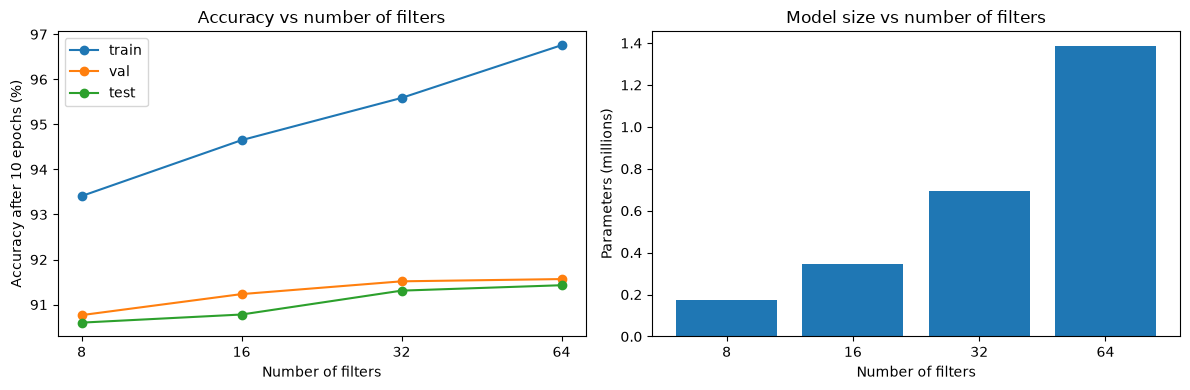

In [ ]:
# A. Test Hyperparameters
from keras.layers import Dropout
import time

def build_cnn(filters=32, dropout=False):
    """Section 3's CNN, with the number of filters and the use of dropout as settings."""
    keras.utils.set_random_seed(SEED)  # a brand-new model with the same starting point for every experiment
    model = Sequential()
    model.add(Input(shape=(28, 28, 1)))
    model.add(Conv2D(filters, kernel_size=(3, 3), activation="relu"))
    model.add(MaxPooling2D(pool_size=(2, 2)))
    model.add(Flatten())
    model.add(Dense(128, activation="relu"))
    if dropout:
        model.add(Dropout(0.5))  # during training, randomly switches off half of the dense layer's outputs
    model.add(Dense(10, activation="softmax"))
    model.compile(loss="categorical_crossentropy", optimizer="adam", metrics=["accuracy"])
    return model


def run_experiment(**settings):
    """Train a fresh model with the given settings; return its results and training history."""
    model = build_cnn(**settings)
    start = time.time()
    history = model.fit(
        X_train, y_train,
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        validation_split=VALIDATION_SPLIT,
        verbose=0,
    )
    train_time = time.time() - start
    test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
    results = {
        **settings,
        "parameters": model.count_params(),
        "train acc (%)": history.history["accuracy"][-1] * 100,
        "val acc (%)": history.history["val_accuracy"][-1] * 100,
        "test acc (%)": test_acc * 100,
        "test loss": test_loss,
        "train time (s)": train_time,
    }
    label = ", ".join(f"{key}={value}" for key, value in settings.items())
    print(f"{label}: validation accuracy {results['val acc (%)']:.2f}%, test accuracy {results['test acc (%)']:.2f}%")
    return results, history


filter_values = [8, 16, 32, 64]
filter_results = []
for filters in filter_values:
    results, _ = run_experiment(filters=filters)
    filter_results.append(results)

filter_df = pd.DataFrame(filter_results).set_index("filters")
display(filter_df.round(3))

# Pick the best value with the validation set, so the test set stays an untouched final check
best_filters = int(filter_df["val acc (%)"].idxmax())
print(f"Best number of filters by validation accuracy: {best_filters}")

fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(12, 4))
for column in ["train acc (%)", "val acc (%)", "test acc (%)"]:
    ax0.plot(filter_values, filter_df[column], marker="o", label=column.replace(" acc (%)", ""))
ax0.set_xscale("log", base=2)
ax0.set_xticks(filter_values, labels=filter_values)
ax0.set_xlabel("Number of filters")
ax0.set_ylabel("Accuracy after 10 epochs (%)")
ax0.set_title("Accuracy vs number of filters")
ax0.legend(loc="best")
ax1.bar([str(f) for f in filter_values], filter_df["parameters"] / 1e6)
ax1.set_xlabel("Number of filters")
ax1.set_ylabel("Parameters (millions)")
ax1.set_title("Model size vs number of filters")
plt.tight_layout()
plt.show()

filters=64, dropout=False: validation accuracy 91.57%, test accuracy 91.43%


filters=64, dropout=True: validation accuracy 91.85%, test accuracy 91.35%


,filters,parameters,train acc (%),val acc (%),test acc (%),test loss,train time (s),train-val gap (pts)
dropout,,,,,,,,
False,64,1386506,96.757,91.567,91.43,0.287,100.133,5.191
True,64,1386506,92.711,91.850,91.35,0.243,134.397,0.861


Use dropout in the final model: True


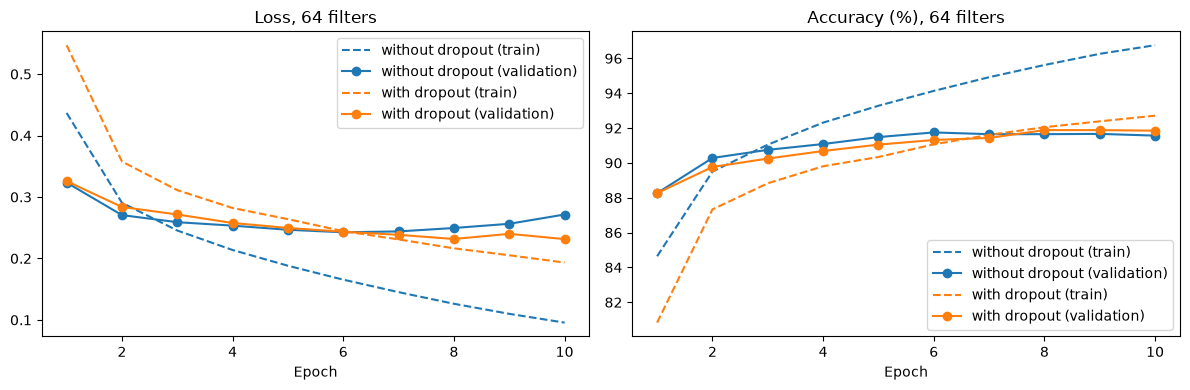

In [ ]:
# B. Test presence or absence of regularization

dropout_results, dropout_histories = [], {}
for dropout in [False, True]:
    results, history = run_experiment(filters=best_filters, dropout=dropout)
    dropout_results.append(results)
    dropout_histories[dropout] = history

dropout_df = pd.DataFrame(dropout_results).set_index("dropout")
dropout_df["train-val gap (pts)"] = dropout_df["train acc (%)"] - dropout_df["val acc (%)"]
display(dropout_df.round(3))

use_dropout = bool(dropout_df["val acc (%)"].idxmax())
print(f"Use dropout in the final model: {use_dropout}")

# Loss and accuracy per epoch: dashed = training set, solid = validation set
epochs = range(1, EPOCHS + 1)
fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(12, 4))
for dropout, color in [(False, "tab:blue"), (True, "tab:orange")]:
    history = dropout_histories[dropout]
    name = "with dropout" if dropout else "without dropout"
    ax0.plot(epochs, history.history["loss"], "--", color=color, label=f"{name} (train)")
    ax0.plot(epochs, history.history["val_loss"], "-o", color=color, label=f"{name} (validation)")
    ax1.plot(epochs, np.array(history.history["accuracy"]) * 100, "--", color=color, label=f"{name} (train)")
    ax1.plot(epochs, np.array(history.history["val_accuracy"]) * 100, "-o", color=color, label=f"{name} (validation)")
ax0.set_title(f"Loss, {best_filters} filters")
ax0.set_xlabel("Epoch")
ax0.legend(loc="best")
ax1.set_title(f"Accuracy (%), {best_filters} filters")
ax1.set_xlabel("Epoch")
ax1.legend(loc="best")
plt.tight_layout()
plt.show()

Reflection: Report on the performance of the models you tested. Did any of the changes you made improve the model's performance? If so, which ones? What do you think contributed to these improvements? Finally, what combination of hyperparameters and regularization techniques yielded the best performance?

Setup: Every run used Section 3's architecture, Adam, 10 epochs, batch size 128, the same 10% validation split and the same random seed, so the setting being tested was the only difference between runs. I chose settings by **validation** accuracy and recorded test accuracy only as a final check, so the test set did not influence the choices. (The 32-filter run reproduces the Section 3 CNN exactly, which confirms the setup is controlled.)

**A. Number of filters (8, 16, 32, 64)**
- Validation accuracy rose with more filters, but with diminishing returns: 90.77% → 91.23% → 91.52% → 91.57% (test: 90.60% → 90.78% → 91.31% → 91.43%).
- Training accuracy rose much faster (93.4% → 96.8%), so the train–validation gap grew from 2.6 to 5.2 points. More filters give the model more capacity to learn useful features, but also more capacity to memorize the training set.
- 64 filters had the best validation accuracy, but only by 0.05 points over 32. That is within run-to-run noise, so 32 filters would be the more efficient choice.

**B. Dropout (rate 0.5) with 64 filters**
- Dropout greatly reduced overfitting. The train–validation gap shrank from 5.2 to 0.9 points, and validation loss kept trending down instead of rising after epoch 6.
- Validation accuracy improved slightly (91.57% → 91.85%) and test loss improved (0.287 → 0.243), so the model is less over-confident when it is wrong. Test accuracy stayed essentially the same (91.43% vs 91.35%, a difference of 8 images).
- Dropout helps because randomly switching off half of the dense layer's outputs during training stops the network from relying on a few specific units, so it has to learn more robust features.

**Best combination:** 64 filters with dropout, which had the highest validation accuracy (91.85%) and the lowest loss. Overall, the changes improved generalization (a smaller gap and lower loss) more than raw accuracy. Beyond about 32 filters, this single-convolution-layer architecture levels off at around 91–92%.

# 5. Training Final Model and Evaluation

In this section, you will train the final model using the best hyperparameters and regularization techniques you found in the previous section. You should:
- [ ] Compile the final model with the best hyperparameters and regularization techniques.
- [ ] Train the final model on the training set and evaluate it on the test set.
- [ ] Report the final model's performance on the test set, including accuracy and any other relevant metrics.

Final model: 64 filters, dropout = True


Model: "sequential_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_7 (Conv2D)               │ (None, 26, 26, 64)     │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 13, 13, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_8 (Flatten)             │ (None, 10816)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 128)            │     1,384,576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,386,506 (5.29 MB)

 Trainable params: 1,386,506 (5.29 MB)

 Non-trainable params: 0 (0.00 B)

... (18 outputs left out)

Epoch 10/10


469/469 - 10s - 21ms/step - accuracy: 0.9264 - loss: 0.2006



Final model test loss:     0.243
Final model test accuracy: 91.34%



              precision    recall  f1-score   support

 T-shirt/top      0.871     0.865     0.868      1000
     Trouser      0.998     0.976     0.987      1000
    Pullover      0.840     0.876     0.858      1000
       Dress      0.912     0.919     0.915      1000
        Coat      0.864     0.848     0.856      1000
      Sandal      0.990     0.973     0.981      1000
       Shirt      0.760     0.756     0.758      1000
     Sneaker      0.945     0.984     0.964      1000
         Bag      0.984     0.982     0.983      1000
  Ankle boot      0.975     0.955     0.965      1000

    accuracy                          0.913     10000
   macro avg      0.914     0.913     0.914     10000
weighted avg      0.914     0.913     0.914     10000

Most common mistakes:
  Shirt        predicted as T-shirt/top  98 times
  T-shirt/top  predicted as Shirt        91 times
  Coat         predicted as Pullover     78 times
  Pullover     predicted as Shirt        61 times
  Shirt        pred

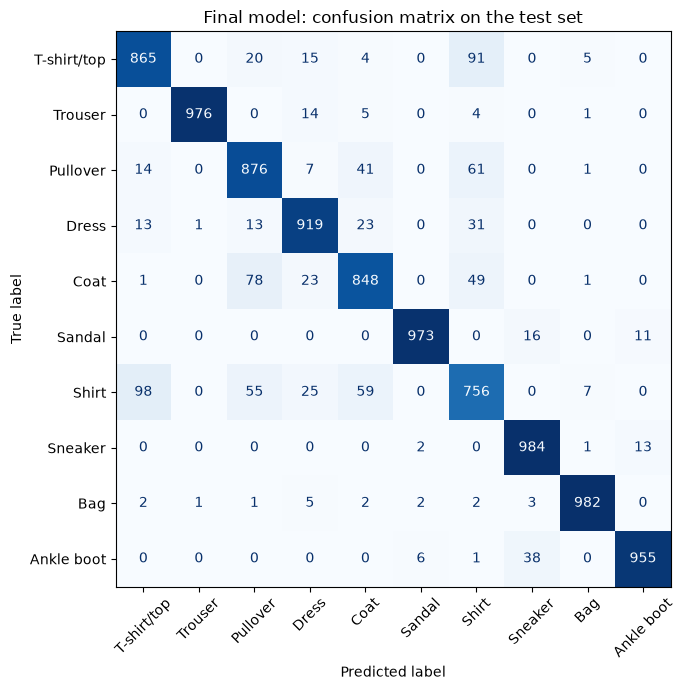

,test accuracy (%),test loss,"test errors (of 10,000)"
Baseline (linear),84.10,0.454,1590
Simple CNN (Section 3),91.31,0.266,869
"Final CNN (64 filters, dropout=True)",91.34,0.243,866


In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# Final model: the best settings found in Section 4
print(f"Final model: {best_filters} filters, dropout = {use_dropout}")
final_model = build_cnn(filters=best_filters, dropout=use_dropout)
final_model.summary()

# The settings are chosen, so the 6,000 validation images are no longer needed for model selection:
final_history = final_model.fit(X_train, y_train, epochs=EPOCHS, batch_size=BATCH_SIZE, verbose=2)

final_loss, final_acc = final_model.evaluate(X_test, y_test, verbose=0)
print(f"\nFinal model test loss:     {final_loss:.3f}")
print(f"Final model test accuracy: {final_acc*100:.2f}%\n")

# Precision, recall and F1-score for each class
true_classes = np.argmax(y_test, axis=1)
final_predictions = np.argmax(final_model.predict(X_test, verbose=0), axis=1)
print(classification_report(true_classes, final_predictions, target_names=class_names, digits=3))

# Most common mistakes (true class -> predicted class)
cm = confusion_matrix(true_classes, final_predictions)
mistakes = cm.copy()
np.fill_diagonal(mistakes, 0)
print("Most common mistakes:")
for flat_index in np.argsort(mistakes, axis=None)[::-1][:5]:
    true_c, pred_c = np.unravel_index(flat_index, mistakes.shape)
    print(f"  {class_names[true_c]:<12} predicted as {class_names[pred_c]:<12} {mistakes[true_c, pred_c]} times")

# Confusion matrix: rows are the true class, columns the predicted class
fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(ax=ax, cmap="Blues", xticks_rotation=45, colorbar=False)
ax.set_title("Final model: confusion matrix on the test set")
plt.tight_layout()
plt.show()

# All models side by side
summary = pd.DataFrame({
    "test accuracy (%)": [baseline_acc * 100, cnn_acc * 100, final_acc * 100],
    "test loss": [baseline_loss, cnn_loss, final_loss],
    "test errors (of 10,000)": [round((1 - acc) * len(X_test)) for acc in [baseline_acc, cnn_acc, final_acc]],
}, index=["Baseline (linear)", "Simple CNN (Section 3)", f"Final CNN ({best_filters} filters, dropout={use_dropout})"])
display(summary.round(3))

Reflection: How does the final model's performance compare to the baseline and the CNN model? What do you think contributed to the final model's performance? If you had time, what other experiments would you run to further improve the model's performance?

The final model (64 filters + dropout, trained on all 60,000 training images) reached **91.34% test accuracy** with a test loss of 0.243:

| Model | Test accuracy | Test loss | Test errors |
|---|---|---|---|
| Baseline (linear) | 84.10% | 0.454 | 1,590 |
| Simple CNN (32 filters) | 91.31% | 0.266 | 869 |
| Final CNN (64 filters + dropout) | 91.34% | 0.243 | 866 |

Compared with the baseline, it is 7.24 points better and makes 724 fewer mistakes, for the same reasons the CNN beat the baseline (convolutions, pooling and non-linearity). Compared with the simple CNN, accuracy is essentially the same (3 fewer errors), but the loss is about 9% lower and the model barely overfits, so it is the more reliable of the two. Neither the extra filters, dropout nor the extra 6,000 training images moved accuracy much. That suggests the main limits are now the architecture (a single convolutional layer) and the data itself.

With more time I would try:
- **A deeper network:** a second Conv2D + MaxPooling block, like the ConvNet in the CNN slides, so the model can build larger features (collars, sleeves) out of the edges found by the first layer. I expect this to help the most.
- **Other hyperparameters:** kernel size (the receptive field), the size of the Dense layer, and the learning rate (for example ReduceLROnPlateau, from the slides).
- **Longer training with early stopping:** with dropout the model was no longer overfitting at epoch 10, so it could train longer, stopping when validation loss stops decreasing (the stopping rule from the slides).

🚨 **Please review our [Assignment Submission Guide](https://github.com/UofT-DSI/onboarding/blob/main/onboarding_documents/submissions.md)** 🚨 for detailed instructions on how to format, branch, and submit your work. Following these guidelines is crucial for your submissions to be evaluated correctly.
### Submission Parameters:
* Submission Due Date: `23:59 PM - 11/09/2026`
* The branch name for your repo should be: `assignment-1`
* What to submit for this assignment:
    * This Jupyter Notebook (assignment_1.ipynb)
    * The Lab 1 notebook (labs/lab_1.ipynb)
    * The Lab 2 notebook (labs/lab_2.ipynb)
    * The Lab 3 notebook (labs/lab_3.ipynb)
* What the pull request link should look like for this assignment: `https://github.com/<your_github_username>/deep_learning/pull/<pr_id>`
* Open a private window in your browser. Copy and paste the link to your pull request into the address bar. Make sure you can see your pull request properly. This helps the technical facilitator and learning support staff review your submission easily.
Checklist:
- [ ] Created a branch with the correct naming convention.
- [ ] Ensured that the repository is public.
- [ ] Reviewed the PR description guidelines and adhered to them.
- [ ] Verify that the link is accessible in a private browser window.
If you encounter any difficulties or have questions, please don't hesitate to reach out to our team via our Slack at `#cohort-7-help-ml`. Our Technical Facilitators and Learning Support staff are here to help you navigate any challenges.